In [5]:
pip install pyts


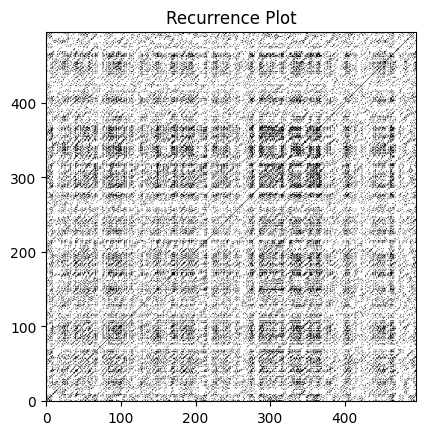


📊 RQA Metrics:
RR: 0.2000
DET: 0.2895
L: 3.3366
Lmax: 496.0000
ENTR: 1.5263
LAM: 0.4229
TT: 2.5723
Vmax: 21.0000
DIV: 0.0020


In [26]:
import numpy as np
from pyts.image import RecurrencePlot
import matplotlib.pyplot as plt
from scipy.stats import entropy as scipy_entropy

# sample eeg
np.random.seed(42)
eeg_signal = np.random.normal(0, 1, 500)
eeg_signal_reshaped = eeg_signal.reshape(1, -1)

# --- Recurrence Plot ---
rp = RecurrencePlot(dimension=3, time_delay=2, threshold='point', percentage=20)
X_rp = rp.transform(eeg_signal_reshaped)[0].astype(int)
N = X_rp.shape[0]

plt.imshow(X_rp, cmap='binary', origin='lower')
plt.title("Recurrence Plot")
plt.show()

# functions
def get_line_lengths(matrix, direction='diagonal', min_length=2):
    lengths = []
    size = matrix.shape[0]

    if direction == 'diagonal':
        for offset in range(-size + 1, size):
            diag = np.diagonal(matrix, offset=offset)
            run = 0
            for val in diag:
                if val:
                    run += 1
                elif run >= min_length:
                    lengths.append(run)
                    run = 0
                else:
                    run = 0
            if run >= min_length:
                lengths.append(run)

    elif direction == 'vertical':
        for col in range(matrix.shape[1]):
            run = 0
            for val in matrix[:, col]:
                if val:
                    run += 1
                elif run >= min_length:
                    lengths.append(run)
                    run = 0
                else:
                    run = 0
            if run >= min_length:
                lengths.append(run)

    return lengths


# --- RQA Metrics ---
def rqa_metrics(R, l_min=2, v_min=2):
    N = R.shape[0]
    total_points = N * N
    recur_points = np.sum(R)

    RR = recur_points / total_points

    diag_lengths = get_line_lengths(R, direction='diagonal', min_length=l_min)
    vert_lengths = get_line_lengths(R, direction='vertical', min_length=v_min)

    # Determinism (DET)
    DET = np.sum(diag_lengths) / recur_points if recur_points > 0 else 0

    # Average Diagonal Line Length (L)
    L = np.mean(diag_lengths) if diag_lengths else 0

    # Longest Diagonal Line (Lmax)
    Lmax = np.max(diag_lengths) if diag_lengths else 0

    # Entropy (ENTR)
    hist_diag = np.bincount(diag_lengths)
    hist_diag = hist_diag[1:]  # remove zero-length
    P = hist_diag / np.sum(hist_diag) if np.sum(hist_diag) > 0 else [0]
    ENTR = scipy_entropy(P)

    # Laminarity (LAM)
    LAM = np.sum(vert_lengths) / recur_points if recur_points > 0 else 0

    # Trapping Time (TT)
    TT = np.mean(vert_lengths) if vert_lengths else 0

    # Longest Vertical Line (Vmax)
    Vmax = np.max(vert_lengths) if vert_lengths else 0

    # Divergence (DIV)
    DIV = 1 / Lmax if Lmax > 0 else 0

    return {
        "RR": RR,
        "DET": DET,
        "L": L,
        "Lmax": Lmax,
        "ENTR": ENTR,
        "LAM": LAM,
        "TT": TT,
        "Vmax": Vmax,
        "DIV": DIV
    }

# ---calculaton of RQA ---
results = rqa_metrics(X_rp)

# ---Results---
print("\n📊 RQA Metrics:")
for key, value in results.items():
    print(f"{key}: {value:.4f}")
